In [20]:
import matplotlib.pyplot as plt
import numpy as np

We define the function and it's derivative. 

In [21]:
def f(x_1, x_2):  #We define our function f(x_1, x_2) = x_1^2 + x_2^2
    return x_1**2 + x_2**2

def df(x_1, x_2):  #We define the gradient of our function f(x_1, x_2)
    return np.array([2*x_1, 2*x_2])

Now, we define the algorithm of gradient descent:


In [22]:
def gradient_descent(df, starting_point, alpha, num_iterations):
    x_1, x_2 = map(float, starting_point)   #change it for x_1, x_2 = map(float, starting_point)??
    points = [(x_1, x_2)]
    
    for i in range(num_iterations):
        gradient = df(x_1, x_2)
        x_1 -= alpha * gradient[0]
        x_2 -= alpha * gradient[1]
        points.append((x_1, x_2))
    
    return points

    Now, having the algorithm of gradient descent, let's experiment with the function, using different starting points and different number of iterations. 

In [23]:
alpha = [0.01, 0.1, 1, 2]
num_iterations = [10, 50, 100, 1000]

In [ ]:
initial_points_1 = [(1,1), (2,2), (1,2), (2,1), (5,5)]
for i in initial_points_1:
    for j in alpha:
        for k in num_iterations:
            min = gradient_descent(df, i, j, k)
            print(f"The minimum is found at: x = ({min[-1][0]:.15f}, {min[-1][1]:.15f}) and is f(x) = {f(min[-1][0], min[-1][1]):.15f} with alpha = {j} and number of iterations = {k}, and starting point = {i}")
        print()

The minimum is found at: x = (0.817072806887547, 0.817072806887547) and is f(x) = 1.335215943510189 with alpha = 0.01 and number of iterations = 10, and starting point = (1, 1)
The minimum is found at: x = (0.364169680087117, 0.364169680087117) and is f(x) = 0.265239111789506 with alpha = 0.01 and number of iterations = 50, and starting point = (1, 1)
The minimum is found at: x = (0.132619555894753, 0.132619555894753) and is f(x) = 0.035175893211443 with alpha = 0.01 and number of iterations = 100, and starting point = (1, 1)
The minimum is found at: x = (0.000000001682967, 0.000000001682967) and is f(x) = 0.000000000000000 with alpha = 0.01 and number of iterations = 1000, and starting point = (1, 1)

The minimum is found at: x = (0.107374182400000, 0.107374182400000) and is f(x) = 0.023058430092137 with alpha = 0.1 and number of iterations = 10, and starting point = (1, 1)
The minimum is found at: x = (0.000014272476927, 0.000014272476927) and is f(x) = 0.000000000407407 with alpha =

C:\Users\Usuario\AppData\Local\Temp\ipykernel_27888\3615356227.py:7: RuntimeWarning: overflow encountered in scalar multiply
  x_1 -= alpha * gradient[0]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_27888\3615356227.py:8: RuntimeWarning: overflow encountered in scalar multiply
  x_2 -= alpha * gradient[1]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_27888\3615356227.py:7: RuntimeWarning: invalid value encountered in scalar subtract
  x_1 -= alpha * gradient[0]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_27888\3615356227.py:8: RuntimeWarning: invalid value encountered in scalar subtract
  x_2 -= alpha * gradient[1]
C:\Users\Usuario\AppData\Local\Temp\ipykernel_27888\2281296617.py:5: RuntimeWarning: overflow encountered in scalar multiply
  return np.array([2*x_1, 2*x_2])


Now, we may look at the paths that gradient descent followed. 

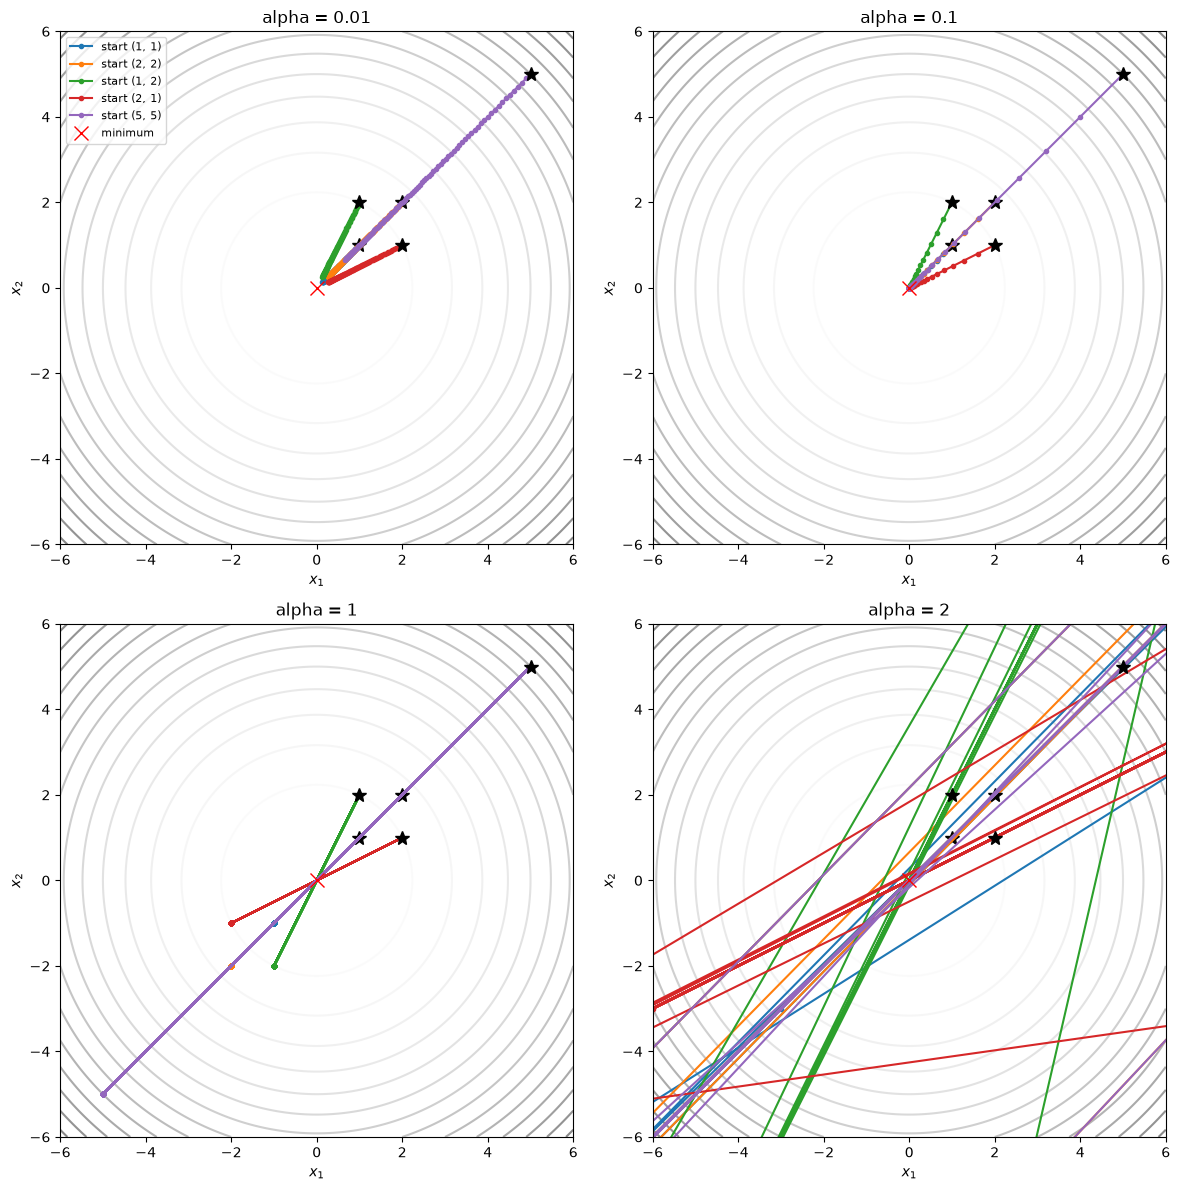

In [54]:
xx = np.linspace(-6, 6, 200)
X1, X2 = np.meshgrid(xx, xx)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, a in zip(axes.flat, alpha):
    ax.contour(X1, X2, f(X1, X2), levels=15, cmap="Greys", alpha=0.5)
    for point in initial_points_1:
        path = np.array(gradient_descent(df, point, a, num_iterations[2]))
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=3, label=f"start {point}")
        ax.plot(*point, "k*", markersize=10)
    ax.plot(0, 0, "rx", markersize=10, label="minimum")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_title(f"alpha = {a}")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()


### 1.1 Questions

**Experiment 1: constant step $\alpha^k = 0.1$, at most 100 iterations**
- Does the algorithm always converge (up to a certain precision) to the only minimum, whatever the starting point $x^0$?
- Is it true that the more iterations, the closer we get to the minimum?
- What path does the gradient descent follow for each starting point?

**Experiment 2: larger steps $\alpha^k = 1$ and $\alpha^k = 2$**
- How does the gradient descent behave with these steps, and why does it perform poorly?
- What does this tell us about the importance of choosing an appropriate $\alpha$?

**Answers:**

## 1.2 A function with multiple minima

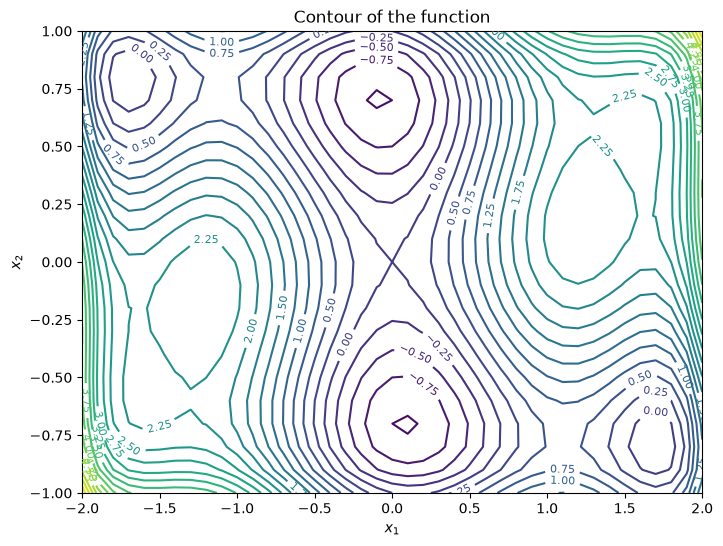

In [26]:
def h(x_1, x_2):
  return x_1**2 * (4-2.1*x_1**2 + (1/3)*x_1**4) + x_1*x_2 + x_2**2 *(-4+4*x_2**2)

def dh(x_1, x_2):
    return np.array([8*x_1-8.4*x_1**3+2*x_1**5+x_2, x_1-8*x_2+16*x_2**3])

x_1 = np.arange(-2, 2+0.1, 0.1)
x_2 = np.arange(-1, 1+0.1, 0.1)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = h(X_1, X_2)

#Below we draw the countour of h(x_1, x_2):
fig, ax = plt.subplots(figsize=(8, 6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the function")
plt.show()

 1. 

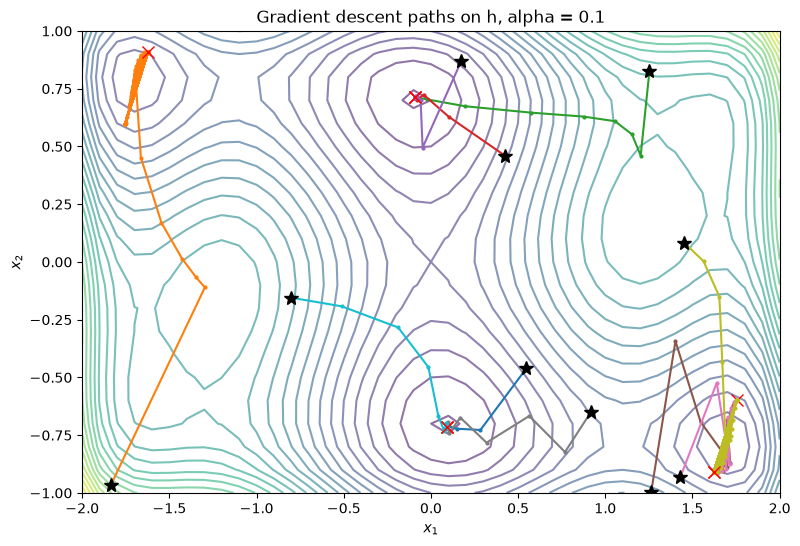

In [27]:
rng = np.random.default_rng(0)  # fixed seed so results are reproducible
initial_points_2 = [(rng.uniform(-2, 2), rng.uniform(-1, 1)) for initial_point in range(10)]


fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_2:
    path = np.array(gradient_descent(dh, point, 0.1, 100))
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on h, alpha = 0.1")
plt.show()

### 1.2 Questions: constant step

- The function is not convex and has several local minima. Which minimum will be found?
- How does the result depend on the starting point $x^0$?
- For each $x^0$ (with $\alpha^k = 0.1$, 100 iterations), to which minimum does the algorithm converge? Is it the one in the valley to which $x^0$ belongs?

**Answers:**

2. 


In [28]:
def gradient_descent_backtrack(f, df, starting_point):
    
    (x_1, x_2) = starting_point
    points = [(x_1, x_2)]
    while True:
        gradient = df(x_1, x_2)
        if np.linalg.norm(gradient) < 1e-5:
            break

        alpha=1
        while f(x_1, x_2) <= f(x_1 - alpha*gradient[0], x_2 - alpha*gradient[1]):
            alpha = alpha/2
        
        x_1 -= alpha*gradient[0]
        x_2 -= alpha*gradient[1]
        points.append((x_1, x_2))

    return points
        

For starting points = (0.5478467492858172, -0.4604265724722594), the number of iterations to reach the minimum is 10
For starting points = (-1.8361059042552212, -0.9669447289429418), the number of iterations to reach the minimum is 11
For starting points = (1.2530809568010897, 0.8255111545554434), the number of iterations to reach the minimum is 12
For starting points = (0.42654310306871945, 0.4589931219679968), the number of iterations to reach the minimum is 9
For starting points = (0.17449996586169148, 0.8701448475755365), the number of iterations to reach the minimum is 9
For starting points = (1.2634142164861286, -0.9945229996597038), the number of iterations to reach the minimum is 16
For starting points = (1.4296171063502774, -0.9328288493890713), the number of iterations to reach the minimum is 17
For starting points = (0.9186217857197763, -0.648688758794882), the number of iterations to reach the minimum is 10
For starting points = (1.4527156893995463, 0.08292244049818343), th

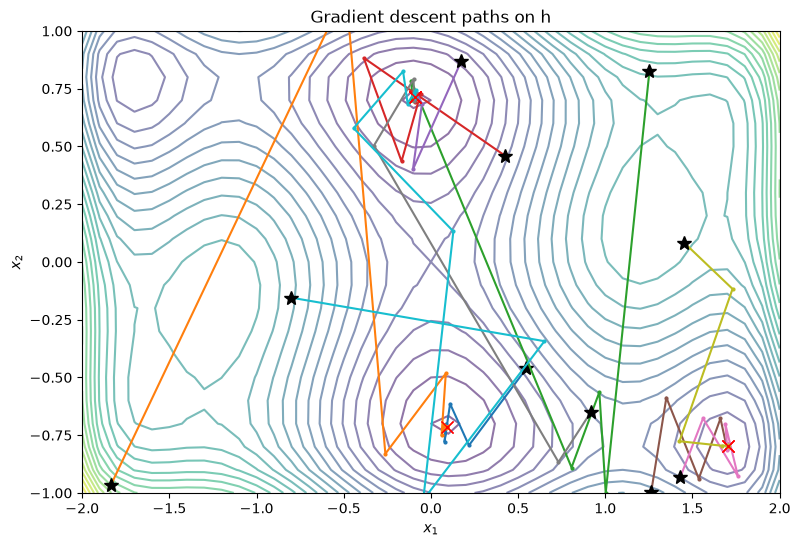

In [29]:

fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_2:
    path = np.array(gradient_descent_backtrack(h, dh, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on h")
plt.show()



### 1.2 Questions: backtracking

Stopping criterion: $\|\nabla f(x^{k+1})\| < 10^{-5}$ (or $|f(x^{k+1}) - f(x^k)| < 10^{-3}$).

- How does the backtracking algorithm perform compared with the constant-step results?
- How many iterations are needed to reach the minimum? 100, or fewer?

**Answers:**

1.3 The Rosenbrock function

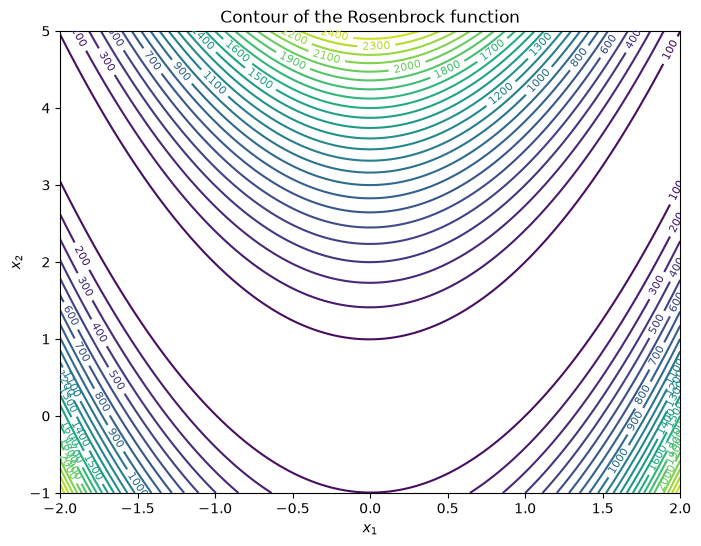

In [30]:
from sympy import symbols, derive_by_array


def R(x_1, x_2):
    return (1-x_1)**2 + 100*(x_2 - x_1**2)**2


x_1, x_2 = symbols ('x_1 x_2') #We compute the gradient using derive_by_array
dR_ = derive_by_array(R(x_1, x_2), (x_1, x_2))

def dR(x_1, x_2):
    return np.array([-400*x_1*(-x_1**2 + x_2) + 2*x_1 - 2, -200*x_1**2 + 200*x_2])

x_1 = np.arange(-2, 2+0.01, 0.01)
x_2 = np.arange(-1, 5+0.01, 0.01)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = R(X_1, X_2)

#Below we draw the countour of R(x_1, x_2):
fig, ax = plt.subplots(figsize=(8,6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the Rosenbrock function")
plt.show()

What does it refers with: You may also draw the gradient information????

In [ ]:
rng = np.random.default_rng(3)  # fixed seed so results are reproducible
initial_points_3 = [(rng.uniform(-2, 2), rng.uniform(-1, 5)) for initial_point in range(10)]
 #MAYBE CHANGE STARTING POINTS BECAUSE IT'S SUPOSSED TO NOT FIND THE MINIMUM?
fig, ax = plt.subplots(figsize = (8,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_3:
    path = np.array(gradient_descent_backtrack(R, dR, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum = {(path[-1])} is {len(path)-1}, where R(minimum_point) = {R(path[-1][0], path[-1][1])}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 5)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent bt paths on Rosenbrock function")
plt.show()

### 1.3 Questions

- Is the backtracking descent robust to different starting points $x^0$? How good is the path it follows?
- How many iterations are performed until the stopping criterion is satisfied (iterations not limited to 100)?
- Once the criterion is satisfied, what values of $x_1$ and $x_2$ were found? Is the algorithm able to reach the minimum $(x_1^*, x_2^*) = (1, 1)$?
- If the criterion stops before reaching the minimum, does lowering the thresholds allow it to be found?
- Is the direction of steepest descent the best direction we may take? Why does gradient descent perform poorly on a badly scaled function?

**Answers:**

## 2. Newton Descent Method

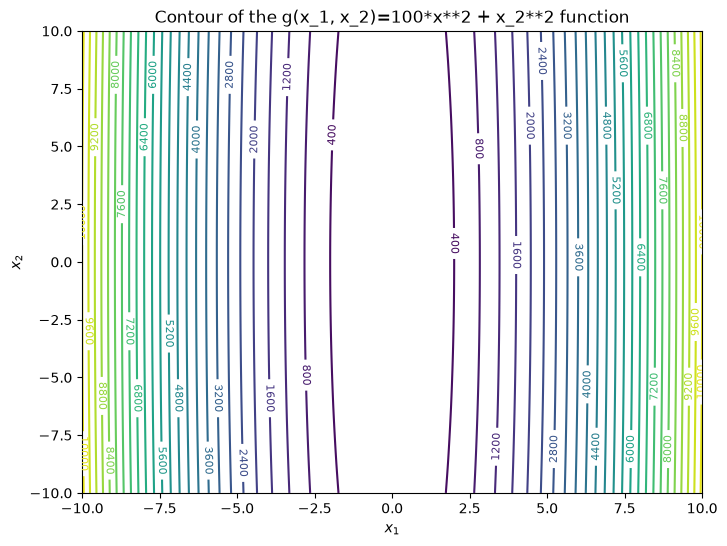

In [37]:
def g(x_1, x_2):
    return 100*x_1**2 + x_2**2

def dg(x_1, x_2):
    return np.array([200*x_1, 2*x_2])

def ddg(x_1, x_2):
    return np.array([[200,0],[0,2]])


x_1 = np.arange(-10, 10+0.1, 0.1)
x_2 = np.arange(-10, 10+0.1, 0.1)
X_1, X_2 = np.meshgrid(x_1, x_2)
Z = g(X_1, X_2)

#Below we draw the countour of g(x_1, x_2):
fig, ax = plt.subplots(figsize=(8,6))
contour = ax.contour(X_1, X_2, Z, levels=30, cmap='viridis')
ax.clabel(contour, inline=True, fontsize=8)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
plt.title("Contour of the g(x_1, x_2)=100*x**2 + x_2**2 function")
plt.show()

For starting points = (8.86112211144735, 0.2265510562872315), the number of iterations to reach the minimum is 496
For starting points = (9.524874114154084, -8.383279522087957), the number of iterations to reach the minimum is 660
For starting points = (2.1471166399005917, -2.4702683124545484), the number of iterations to reach the minimum is 602
For starting points = (6.038024139716146, -6.509443677119431), the number of iterations to reach the minimum is 643
For starting points = (7.432705483753129, 0.8788280152699635), the number of iterations to reach the minimum is 558
For starting points = (8.044301594319766, -0.45692952321587477), the number of iterations to reach the minimum is 528
For starting points = (-1.390074445411738, 5.778934350886589), the number of iterations to reach the minimum is 643
For starting points = (9.683059998622426, -2.605484146951424), the number of iterations to reach the minimum is 607
For starting points = (9.378657386324697, 8.580527755308388), the num

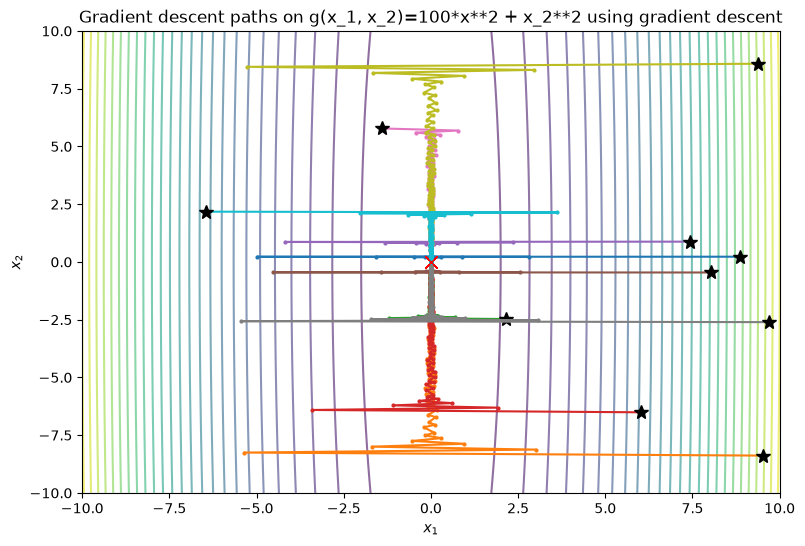

In [53]:
rng = np.random.default_rng(4)  # fixed seed so results are reproducible
initial_points_4 = [(rng.uniform(-10, 10), rng.uniform(-10, 10)) for initial_point in range(10)]

fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_4:
    path = np.array(gradient_descent_backtrack(g, dg, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on g(x_1, x_2)=100*x**2 + x_2**2 using gradient descent")
plt.show()


In [51]:
def newton_descent(f, df, ddf, starting_point):
    x_1, x_2 = map(float, starting_point)
    points = [(x_1, x_2)]
    while True:
        gradient = df(x_1, x_2)
        hessian = ddf(x_1, x_2)
        d = np.linalg.solve(hessian, gradient)
        if np.linalg.norm(gradient) < 1e-5:
            break

        alpha = 1 
        while f(x_1, x_2) <= f(x_1-alpha*d[0], x_2 - alpha*d[1]):
            alpha = alpha/2

        x_1 -= alpha*d[0]
        x_2 -= alpha*d[1]
        points.append((x_1, x_2))

    return points


For starting points = (8.86112211144735, 0.2265510562872315), the number of iterations to reach the minimum is 1
For starting points = (9.524874114154084, -8.383279522087957), the number of iterations to reach the minimum is 1
For starting points = (2.1471166399005917, -2.4702683124545484), the number of iterations to reach the minimum is 1
For starting points = (6.038024139716146, -6.509443677119431), the number of iterations to reach the minimum is 1
For starting points = (7.432705483753129, 0.8788280152699635), the number of iterations to reach the minimum is 1
For starting points = (8.044301594319766, -0.45692952321587477), the number of iterations to reach the minimum is 1
For starting points = (-1.390074445411738, 5.778934350886589), the number of iterations to reach the minimum is 1
For starting points = (9.683059998622426, -2.605484146951424), the number of iterations to reach the minimum is 1
For starting points = (9.378657386324697, 8.580527755308388), the number of iteration

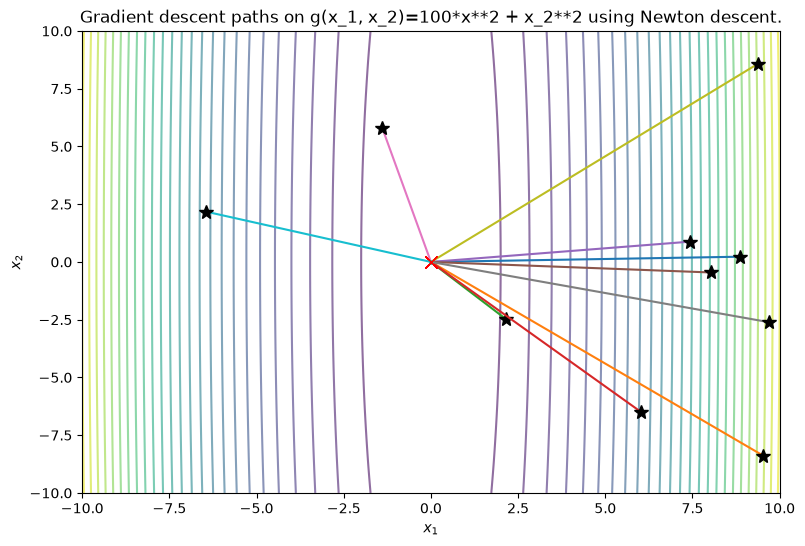

In [52]:
fig, ax = plt.subplots(figsize = (9,6))
ax.contour(X_1, X_2, Z, levels = 30, cmap = "viridis", alpha = 0.6)
for point in initial_points_4:
    path = np.array(newton_descent(g, dg, ddg, point))
    print(f"For starting points = {point}, the number of iterations to reach the minimum is {len(path)-1}")
    ax.plot(path[:,0], path[:,1], "o-", markersize = 2)
    ax.plot(*point, "k*", markersize = 10)
    ax.plot(*path[-1], "rx", markersize=8)    # where each path ends
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Gradient descent paths on g(x_1, x_2)=100*x**2 + x_2**2 using Newton descent.")
plt.show()

2.2. Function with multiple minima

In [ ]:
initial_points_2

def newton_descent_mod(f, df, ddf, starting_point):
    x_1, x_2 = map(float, starting_point)
    points = [(x_1, x_2)]
    while True:

        gradient = df(x_1, x_2)
        hessian = ddf(x_1, x_2)

        if np.all(np.linalg.eigvals(hessian) > 0):
            d = np.linalg.solve(hessian, gradient)
        else:
            d = gradient
        if np.linalg.norm(gradient) < 1e-5:
            break

        alpha = 1 
        
        while f(x_1, x_2) <= f(x_1-alpha*d[0], x_2 - alpha*d[1]):
            alpha = alpha/2

        x_1 -= alpha*d[0]
        x_2 -= alpha*d[1]
        points.append((x_1, x_2))

    return points

### 2.1 Questions: $f(x) = 100x_1^2 + x_2^2$

- How many steps does gradient descent with backtracking need to satisfy $\|\nabla f(x^{k+1})\| < 10^{-5}$ from a given $x^0$?
- How many steps does the Newton method need, with the same backtracking and the same starting points?
- How do the two iteration counts compare, and what path does each method follow?

**Answers:**

### 2.2 Questions: function with multiple minima

- Starting from an $x^0$ "far away" from a minimum, how many iterations does gradient descent need to reach it?
- In the combined Newton-gradient algorithm, which method is used at each iteration (red dots = gradient, green dots = Newton)?
- Is Newton mostly used "near" the minimum, and why?
- How do the combined method and the classical gradient descent compare in number of iterations and in the path followed?

**Answers:**

### 2.3 Questions: Rosenbrock function

- With the same starting points as in 1.3, how many iterations does the combined Newton-gradient algorithm need to reach the minimum?
- Which method (Newton or gradient) is used at each iteration?
- Does Newton reach the minimum $(1, 1)$? How does it compare with the gradient descent, which jumps from one side of the valley to the other?

**Answers:**